# Physics-Informed Masked Multi-Task Learning (PIM-MTL)
## End-to-End Concrete Strength Prediction & Analysis Pipeline

**Dataset:** ConcreteXAI (4,420 multivariate experimental specimens)  
**Targets:** 
- $C_s$: Compressive Strength (MPa) [100% observed]
- $T_s$: Splitting Tensile Strength (MPa) [78.3% observed, 21.7% missing]
- $F_s$: Flexural Strength / Modulus of Rupture (MPa) [39.8% observed, 60.2% missing]

---

### Project Overview
In structural concrete engineering, mechanical performance is governed by compressive strength ($C_s$), splitting tensile strength ($T_s$), and flexural strength ($F_s$). Conventional machine learning pipelines discard incomplete samples (losing >60% of data) or train unconstrained disjoint models that produce physically impossible predictions (e.g. $T_s \ge C_s$).

**PIM-MTL** resolves this by uniting two complementary mechanisms:
1. **Masked Multi-Task Gradient Gating:** Exploits shared latent representations across all 4,420 mixes while zeroing empirical error gradients on unobserved strength labels.
2. **Differentiable Physics Ratio Regularization:** Constrains strength ratios within established ACI design code boundaries ($0.06 \le \hat{T}_s / \hat{C}_s \le 0.18$ and $0.08 \le \hat{F}_s / \hat{C}_s \le 0.25$) on **all samples**, even when tensile or flexural ground truth is missing.


## 1. Imports and Environment Setup
We import the required standard scientific libraries (NumPy, Pandas, Scikit-Learn, PyTorch, Matplotlib, Seaborn) and configure deterministic seeds and computation device.


In [1]:
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

# Ensure utils module can be imported from parent directory
notebook_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(notebook_dir, ".."))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Set random seed for full reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Version : {torch.__version__}")
print(f"Compute Device  : {device}")

# Styling for inline figures
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10


PyTorch Version : 2.13.0+cu130
Compute Device  : cuda


## 2. Data Loading
We load the `Data.csv` dataset and clean string columns.


In [2]:
def load_dataset(filepath: str) -> pd.DataFrame:
    """Load ConcreteXAI CSV, strip whitespace from categorical strings."""
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Dataset not found at: {filepath}")
    
    df = pd.read_csv(filepath)
    string_cols = df.select_dtypes(include=["object"]).columns
    for col in string_cols:
        df[col] = df[col].astype(str).str.strip()
    return df

data_path = os.path.join(project_root, "Data.csv")
df = load_dataset(data_path)
print(f"Dataset successfully loaded from: {data_path}")
print(f"Total Rows: {len(df):,} | Total Columns: {df.shape[1]}")
df.head()


Dataset successfully loaded from: c:\Users\jeetu\projects\Capstone\3rdYearsem5\Data.csv
Total Rows: 4,420 | Total Columns: 12


C:\Users\jeetu\AppData\Local\Temp\ipykernel_27156\439123685.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_cols = df.select_dtypes(include=["object"]).columns


,id,Type_of_cement,Brand,Additives,Type_of_aggregates,Design_Fc_Mpa,Curing_age_days,Cs_Mpa,Ts_Mpa,Fs_Mpa,Er_ohm-cm,UPV_m/s
0,0,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.2154,0.5609,NaN,5.8654,2440.2989
1,1,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.1528,0.5727,NaN,5.9471,2417.9562
2,2,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.6877,0.5826,NaN,5.9965,2429.9277
3,3,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.1476,0.5910,NaN,5.8751,2435.0202
4,4,CPO 30R RS BRA,CEMEX,Opuntia_ficus_indica,Rounded,25,3,5.3406,0.5698,NaN,5.8654,2408.7969


## 3. Data Inspection and Analysis
We examine feature types, dataset dimensions, target coverage, missingness percentage, and summary statistics.


In [3]:
# Schema definitions
CATEGORICAL_COLS = ["Type_of_cement", "Brand", "Additives", "Type_of_aggregates"]
NUMERICAL_COLS = ["Design_Fc_Mpa", "Curing_age_days", "Er_ohm-cm", "UPV_m/s"]
TARGET_COLS = ["Cs_Mpa", "Ts_Mpa", "Fs_Mpa"]

print("--- Column Summary ---")
print(f"Categorical Features ({len(CATEGORICAL_COLS)}): {CATEGORICAL_COLS}")
print(f"Numerical Features   ({len(NUMERICAL_COLS)}): {NUMERICAL_COLS}")
print(f"Target Properties    ({len(TARGET_COLS)}): {TARGET_COLS}")

# Missingness audit table
audit_data = []
for col in df.columns:
    n_present = df[col].notna().sum()
    n_missing = df[col].isna().sum()
    pct_missing = (n_missing / len(df)) * 100.0
    dtype = df[col].dtype
    audit_data.append({
        "Feature": col,
        "Type": dtype,
        "Present": n_present,
        "Missing": n_missing,
        "% Missing": f"{pct_missing:.1f}%"
    })

audit_df = pd.DataFrame(audit_data)
print("\n--- Missingness & Feature Types ---")
display(audit_df)

print("\n--- Numerical Predictors Summary ---")
display(df[NUMERICAL_COLS].describe().round(2))

print("\n--- Mechanical Target Properties Summary ---")
display(df[TARGET_COLS].describe().round(2))


--- Column Summary ---
Categorical Features (4): ['Type_of_cement', 'Brand', 'Additives', 'Type_of_aggregates']
Numerical Features   (4): ['Design_Fc_Mpa', 'Curing_age_days', 'Er_ohm-cm', 'UPV_m/s']
Target Properties    (3): ['Cs_Mpa', 'Ts_Mpa', 'Fs_Mpa']

--- Missingness & Feature Types ---


,Feature,Type,Present,Missing,% Missing
0,id,int64,4420,0,0.0%
1,Type_of_cement,str,4420,0,0.0%
2,Brand,str,4420,0,0.0%
3,Additives,str,4420,0,0.0%
4,Type_of_aggregates,str,4420,0,0.0%
5,Design_Fc_Mpa,int64,4420,0,0.0%
6,Curing_age_days,int64,4420,0,0.0%
7,Cs_Mpa,float64,4420,0,0.0%
8,Ts_Mpa,float64,3460,960,21.7%
9,Fs_Mpa,float64,1760,2660,60.2%



--- Numerical Predictors Summary ---


,Design_Fc_Mpa,Curing_age_days,Er_ohm-cm,UPV_m/s
count,4420.00,4420.00,4420.00,4420.00
mean,28.96,40.44,6.76,3808.96
std,3.51,33.31,2.97,561.04
min,25.00,3.00,1.83,2345.98
25%,25.00,14.00,4.64,3364.67
50%,28.00,28.00,6.07,3722.88
75%,30.00,60.00,7.46,4357.10
max,35.00,120.00,16.17,4666.35



--- Mechanical Target Properties Summary ---


,Cs_Mpa,Ts_Mpa,Fs_Mpa
count,4420.00,3460.00,1760.00
mean,31.19,2.48,3.42
std,9.59,0.88,2.37
min,5.08,0.53,0.34
25%,24.96,2.05,1.17
50%,31.85,2.36,3.14
75%,36.08,2.94,5.56
max,55.71,5.27,8.09


## 4. Data Preprocessing
To prevent data leakage, we perform an 80/20 train/test split before fitting any transformers:
1. **Categorical Features:** One-Hot Encoded with `handle_unknown='ignore'`.
2. **Numerical Features:** Scaled using `RobustScaler` (median & IQR), which handles extreme skew in Electrical Resistivity (`Er_ohm-cm`).
3. **Target Properties:** Target scalers are fitted **strictly on observed values** for each target. Unobserved values are masked with $m_{ij}=0.0$ and assigned a placeholder value of $0.0$.


In [4]:
# Step 1: Train / Test Split (Strictly isolated)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED)
print(f"Train split: {len(train_df):,} samples | Test split: {len(test_df):,} samples")

# Step 2: One-Hot Encoding for Categorical Predictors
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
cat_train = ohe.fit_transform(train_df[CATEGORICAL_COLS])
cat_test = ohe.transform(test_df[CATEGORICAL_COLS])

# Step 3: RobustScaler for Continuous Predictors
scaler_x = RobustScaler()
num_train = scaler_x.fit_transform(train_df[NUMERICAL_COLS])
num_test = scaler_x.transform(test_df[NUMERICAL_COLS])

# Concatenate features into feature matrices X
X_train = np.hstack([num_train, cat_train]).astype(np.float32)
X_test = np.hstack([num_test, cat_test]).astype(np.float32)
input_dim = X_train.shape[1]
print(f"Total Preprocessed Input Feature Dimension: {input_dim}")

# Step 4: Targets and Binary Observation Masks
y_train_raw = train_df[TARGET_COLS].to_numpy(dtype=np.float32)
y_test_raw = test_df[TARGET_COLS].to_numpy(dtype=np.float32)

mask_train = (~np.isnan(y_train_raw)).astype(np.float32)
mask_test = (~np.isnan(y_test_raw)).astype(np.float32)

# Step 5: Fold-isolated Target Scalers (fitted exclusively on observed values)
target_scalers = {}
target_centers = np.zeros(3, dtype=np.float32)
target_scales = np.ones(3, dtype=np.float32)
y_train_scaled = np.zeros_like(y_train_raw)
y_test_scaled = np.zeros_like(y_test_raw)

for i, col in enumerate(TARGET_COLS):
    sc = RobustScaler()
    obs_vals_train = y_train_raw[mask_train[:, i] == 1.0, i].reshape(-1, 1)
    sc.fit(obs_vals_train)
    target_scalers[col] = sc
    target_centers[i] = sc.center_[0]
    target_scales[i] = sc.scale_[0]
    
    # Scale observed targets; unobserved stay 0.0
    tr_obs = mask_train[:, i] == 1.0
    y_train_scaled[tr_obs, i] = sc.transform(y_train_raw[tr_obs, i].reshape(-1, 1)).ravel()
    
    te_obs = mask_test[:, i] == 1.0
    y_test_scaled[te_obs, i] = sc.transform(y_test_raw[te_obs, i].reshape(-1, 1)).ravel()

preprocessor_metadata = {
    "ohe": ohe,
    "scaler_x": scaler_x,
    "target_scalers": target_scalers,
    "target_centers": target_centers,
    "target_scales": target_scales,
    "input_dim": input_dim,
}

print(f"Target Centers (Medians MPa) : {target_centers}")
print(f"Target Scales  (IQRs MPa)    : {target_scales}")


Train split: 3,536 samples | Test split: 884 samples
Total Preprocessed Input Feature Dimension: 19
Target Centers (Medians MPa) : [31.8438     2.3713999  3.1381   ]
Target Scales  (IQRs MPa)    : [11.085499   0.8661248  4.3878   ]


## 5. Exploratory Data Analysis
We generate inline visualizations to inspect:
1. Target missingness profile across the three mechanical properties.
2. Distribution of continuous features and strength targets.
3. Ground truth mechanical strength ratios ($R_t = T_s / C_s$ and $R_f = F_s / C_s$) vs ACI code limits.
4. Correlation matrix among continuous variables.


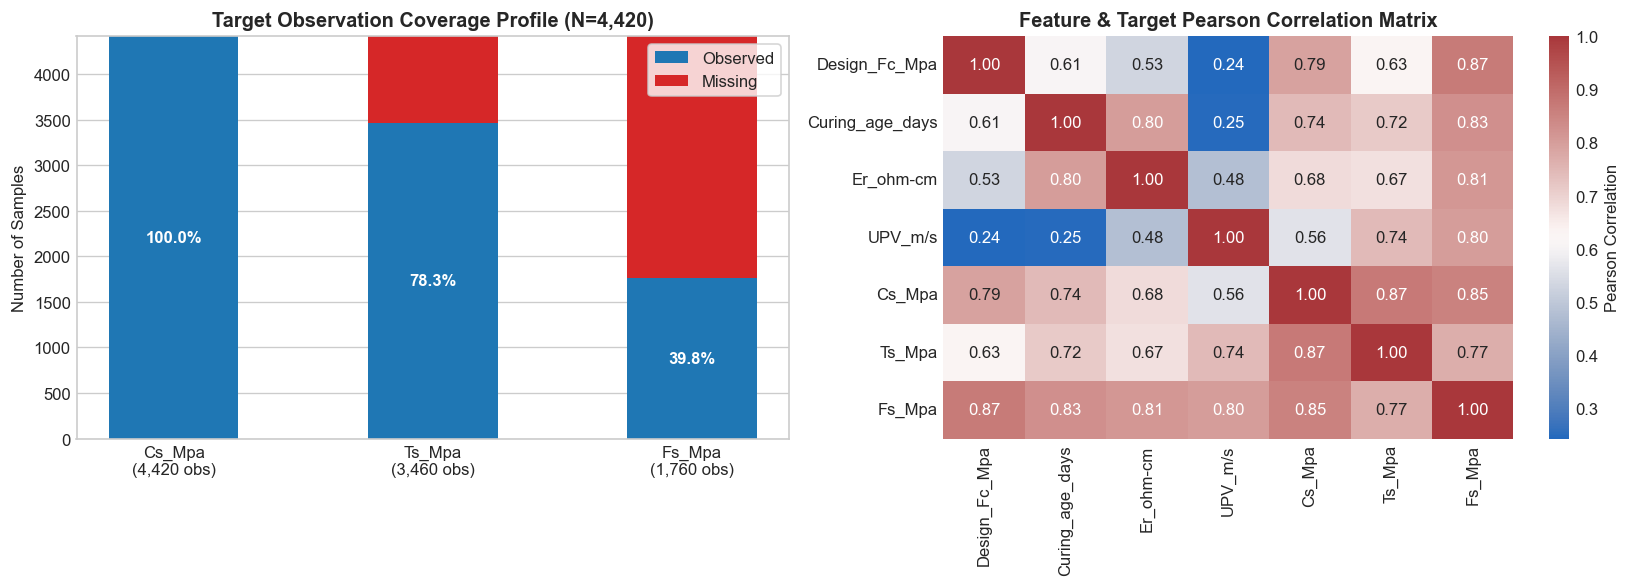

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Target Missingness Bar Plot
missing_counts = [df[col].isna().sum() for col in TARGET_COLS]
observed_counts = [df[col].notna().sum() for col in TARGET_COLS]
x_pos = np.arange(len(TARGET_COLS))

axes[0].bar(x_pos, observed_counts, label="Observed", color="#1f77b4", width=0.5)
axes[0].bar(x_pos, missing_counts, bottom=observed_counts, label="Missing", color="#d62728", width=0.5)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels([f"{c}\n({observed_counts[i]:,} obs)" for i, c in enumerate(TARGET_COLS)])
axes[0].set_ylabel("Number of Samples")
axes[0].set_title("Target Observation Coverage Profile (N=4,420)", fontweight="bold")
axes[0].legend(frameon=True)
for i in range(len(TARGET_COLS)):
    obs_pct = (observed_counts[i] / len(df)) * 100
    axes[0].text(i, observed_counts[i] / 2, f"{obs_pct:.1f}%", ha="center", va="center", color="white", fontweight="bold")

# Subplot 2: Correlation Heatmap of Continuous Predictors & Targets
corr_cols = NUMERICAL_COLS + TARGET_COLS
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="vlag", ax=axes[1], cbar_kws={'label': 'Pearson Correlation'})
axes[1].set_title("Feature & Target Pearson Correlation Matrix", fontweight="bold")

plt.tight_layout()
plt.show()


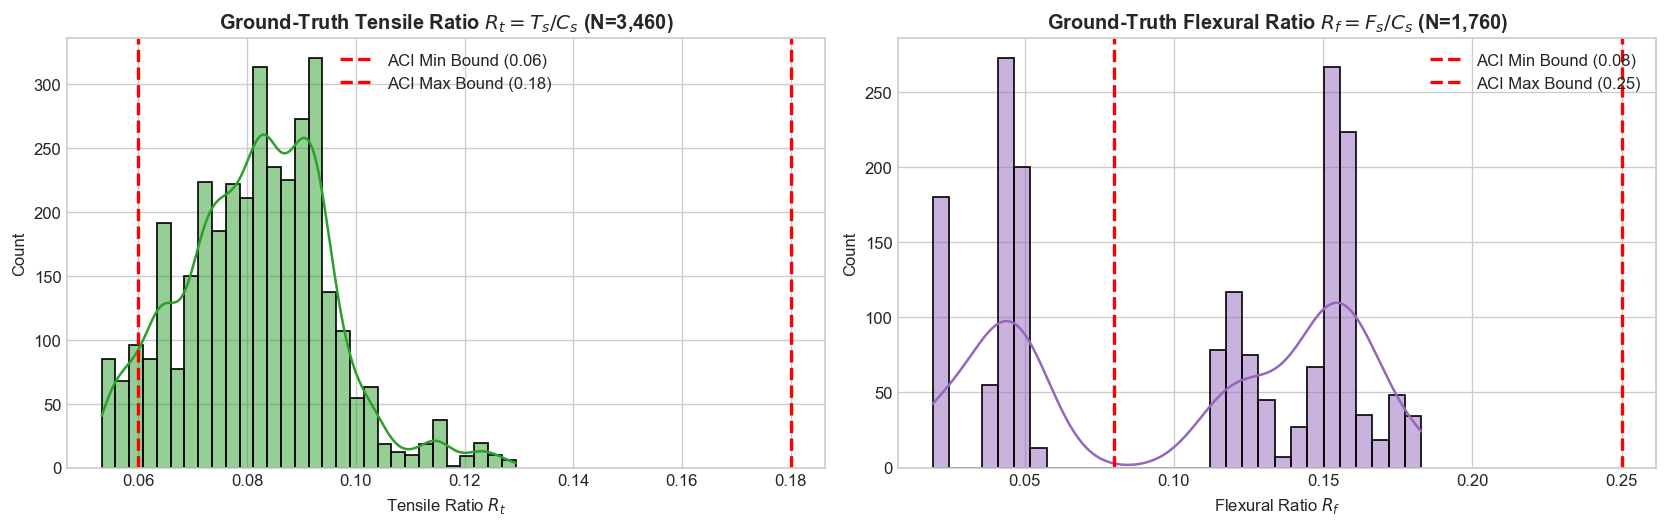

In [6]:
# Ground-truth strength ratio distributions compared to ACI design code bounds
df_clean = df.copy()
df_clean["Rt"] = df_clean["Ts_Mpa"] / df_clean["Cs_Mpa"]
df_clean["Rf"] = df_clean["Fs_Mpa"] / df_clean["Cs_Mpa"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Tensile ratio Rt = Ts / Cs
rt_valid = df_clean["Rt"].dropna()
sns.histplot(rt_valid, kde=True, ax=axes[0], color="#2ca02c", bins=30)
axes[0].axvline(0.06, color="red", linestyle="--", linewidth=2, label="ACI Min Bound (0.06)")
axes[0].axvline(0.18, color="red", linestyle="--", linewidth=2, label="ACI Max Bound (0.18)")
axes[0].set_title(f"Ground-Truth Tensile Ratio $R_t = T_s / C_s$ (N={len(rt_valid):,})", fontweight="bold")
axes[0].set_xlabel("Tensile Ratio $R_t$")
axes[0].legend()

# Flexural ratio Rf = Fs / Cs
rf_valid = df_clean["Rf"].dropna()
sns.histplot(rf_valid, kde=True, ax=axes[1], color="#9467bd", bins=30)
axes[1].axvline(0.08, color="red", linestyle="--", linewidth=2, label="ACI Min Bound (0.08)")
axes[1].axvline(0.25, color="red", linestyle="--", linewidth=2, label="ACI Max Bound (0.25)")
axes[1].set_title(f"Ground-Truth Flexural Ratio $R_f = F_s / C_s$ (N={len(rf_valid):,})", fontweight="bold")
axes[1].set_xlabel("Flexural Ratio $R_f$")
axes[1].legend()

plt.tight_layout()
plt.show()


## 6. Model and Loss Function Setup
We import the modular `PIM_MTL_Net` architecture and `PIM_MTL_Loss` from `utils`.

### Mathematical Formulation
The joint optimization objective is:
$$\mathcal{L}_{total} = \mathcal{L}_{data} + \lambda_{phys} \mathcal{L}_{phys}$$

1. **Masked Empirical Data Loss:**
$$\mathcal{L}_{data} = \sum_{j \in \{Cs, Ts, Fs\}} w_j \frac{\sum_{i=1}^N m_{ij} (y_{ij} - \hat{y}_{ij})^2}{\max(1, \sum_{i=1}^N m_{ij})}$$
where $m_{ij} \in \{0, 1\}$ is the binary mask, zeroing gradients for unobserved strength measurements.

2. **Differentiable Physics Ratio Penalty:**
$$R_t = \frac{\hat{T}_s}{\hat{C}_s + \epsilon}, \quad R_f = \frac{\hat{F}_s}{\hat{C}_s + \epsilon}$$
$$\mathcal{L}_{phys} = \frac{1}{N} \sum_{i=1}^N \left[ \text{ReLU}(R_{t,i} - 0.18)^2 + \text{ReLU}(0.06 - R_{t,i})^2 + \text{ReLU}(R_{f,i} - 0.25)^2 + \text{ReLU}(0.08 - R_{f,i})^2 \right]$$


In [7]:
from utils.losses import PIM_MTL_Loss
from utils.models import PIM_MTL_Net

# Initialize model
model = PIM_MTL_Net(
    input_dim=input_dim,
    hidden_dims=[128, 64, 32],
    dropout=0.2,
    use_batch_norm=True
).to(device)

# Initialize loss function with target centers and scales for differentiable denormalization
criterion = PIM_MTL_Loss(
    task_weights={"Cs": 1.0, "Ts": 1.2, "Fs": 1.5},
    lambda_phys=0.5,
    rt_bounds=(0.06, 0.18),
    rf_bounds=(0.08, 0.25),
    normalization="per_task",
    target_centers=target_centers,
    target_scales=target_scales
).to(device)

print("PIM_MTL_Net Architecture:")
print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal Trainable Parameters: {total_params:,}")


PIM_MTL_Net Architecture:
PIM_MTL_Net(
  (fc1): Linear(in_features=19, out_features=128, bias=True)
  (bn1): SafeBatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (act1): GELU(approximate='none')
  (drop1): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (bn2): SafeBatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (act2): GELU(approximate='none')
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (head_cs): Linear(in_features=32, out_features=1, bias=True)
  (head_ts): Linear(in_features=32, out_features=1, bias=True)
  (head_fs): Linear(in_features=32, out_features=1, bias=True)
)

Total Trainable Parameters: 13,379


## 7. Training
We configure the DataLoader, Adam optimizer, Learning Rate Scheduler, and gradient clipping, then execute the full training loop.


In [8]:
BATCH_SIZE = 64
EPOCHS = 60
LR = 1e-3

# PyTorch DataLoaders
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train_scaled, dtype=torch.float32),
    torch.tensor(mask_train, dtype=torch.float32)
)
test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test_scaled, dtype=torch.float32),
    torch.tensor(mask_test, dtype=torch.float32)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)

# History tracking
history = {
    "epoch": [],
    "train_total": [], "train_data": [], "train_phys": [],
    "val_total": [], "val_data": [], "val_phys": []
}

print(f"Starting Training for {EPOCHS} Epochs on {device}...")
for epoch in range(1, EPOCHS + 1):
    # Training pass
    model.train()
    tr_total, tr_data, tr_phys = 0.0, 0.0, 0.0
    for bx, by, bm in train_loader:
        bx, by, bm = bx.to(device), by.to(device), bm.to(device)
        optimizer.zero_grad()
        preds = model(bx)
        loss, l_data, l_phys = criterion(preds, by, bm)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        
        tr_total += loss.item() * len(bx)
        tr_data += l_data.item() * len(bx)
        tr_phys += l_phys.item() * len(bx)
    
    scheduler.step()
    n_tr = len(X_train)
    tr_total /= n_tr
    tr_data /= n_tr
    tr_phys /= n_tr
    
    # Validation pass
    model.eval()
    val_total, val_data, val_phys = 0.0, 0.0, 0.0
    with torch.no_grad():
        for bx, by, bm in test_loader:
            bx, by, bm = bx.to(device), by.to(device), bm.to(device)
            preds = model(bx)
            v_loss, v_data, v_phys = criterion(preds, by, bm)
            val_total += v_loss.item() * len(bx)
            val_data += v_data.item() * len(bx)
            val_phys += v_phys.item() * len(bx)
            
    n_te = len(X_test)
    val_total /= n_te
    val_data /= n_te
    val_phys /= n_te
    
    # Record history
    history["epoch"].append(epoch)
    history["train_total"].append(tr_total)
    history["train_data"].append(tr_data)
    history["train_phys"].append(tr_phys)
    history["val_total"].append(val_total)
    history["val_data"].append(val_data)
    history["val_phys"].append(val_phys)
    
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:03d}/{EPOCHS} | Train Total: {tr_total:.4f} (Data: {tr_data:.4f}, Phys: {tr_phys:.4f}) | "
              f"Val Total: {val_total:.4f} (Data: {val_data:.4f}, Phys: {val_phys:.4f})")


Starting Training for 60 Epochs on cuda...


Epoch 001/60 | Train Total: 1.6800 (Data: 1.6739, Phys: 0.0121) | Val Total: 0.1165 (Data: 0.1161, Phys: 0.0007)


Epoch 010/60 | Train Total: 0.1325 (Data: 0.1324, Phys: 0.0003) | Val Total: 0.0581 (Data: 0.0580, Phys: 0.0001)


Epoch 020/60 | Train Total: 0.1091 (Data: 0.1089, Phys: 0.0004) | Val Total: 0.0486 (Data: 0.0484, Phys: 0.0004)


Epoch 030/60 | Train Total: 0.0857 (Data: 0.0855, Phys: 0.0003) | Val Total: 0.0378 (Data: 0.0377, Phys: 0.0003)


Epoch 040/60 | Train Total: 0.0841 (Data: 0.0840, Phys: 0.0003) | Val Total: 0.0368 (Data: 0.0366, Phys: 0.0004)


Epoch 050/60 | Train Total: 0.0780 (Data: 0.0779, Phys: 0.0004) | Val Total: 0.0340 (Data: 0.0339, Phys: 0.0004)


Epoch 060/60 | Train Total: 0.0741 (Data: 0.0739, Phys: 0.0004) | Val Total: 0.0347 (Data: 0.0345, Phys: 0.0003)


## 8. Training Monitoring
We plot the convergence curves across training and validation splits for Total Loss, Masked Data Loss, and Physics Ratio Penalty.


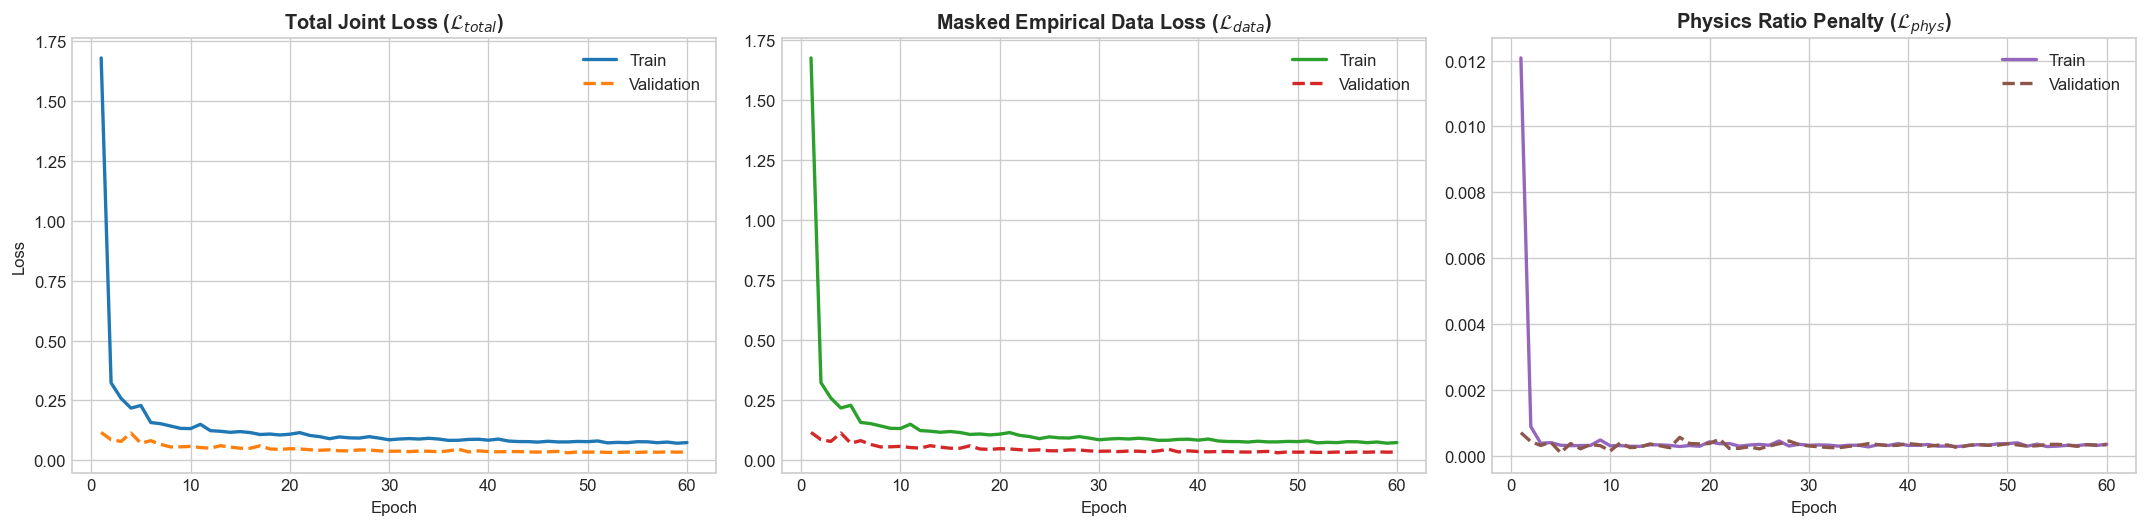

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Total Loss
axes[0].plot(history["epoch"], history["train_total"], label="Train", color="#1f77b4", lw=2)
axes[0].plot(history["epoch"], history["val_total"], label="Validation", color="#ff7f0e", lw=2, linestyle="--")
axes[0].set_title(r"Total Joint Loss ($\mathcal{L}_{total}$)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Masked Data Loss
axes[1].plot(history["epoch"], history["train_data"], label="Train", color="#2ca02c", lw=2)
axes[1].plot(history["epoch"], history["val_data"], label="Validation", color="#d62728", lw=2, linestyle="--")
axes[1].set_title(r"Masked Empirical Data Loss ($\mathcal{L}_{data}$)", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].legend()

# Physics Penalty
axes[2].plot(history["epoch"], history["train_phys"], label="Train", color="#9467bd", lw=2)
axes[2].plot(history["epoch"], history["val_phys"], label="Validation", color="#8c564b", lw=2, linestyle="--")
axes[2].set_title(r"Physics Ratio Penalty ($\mathcal{L}_{phys}$)", fontweight="bold")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
plt.show()


## 9. Visualization of Results
We generate parity plots (Predicted vs. Actual) and residual distributions on the unseen test set, denormalized back to true physical units (MPa).


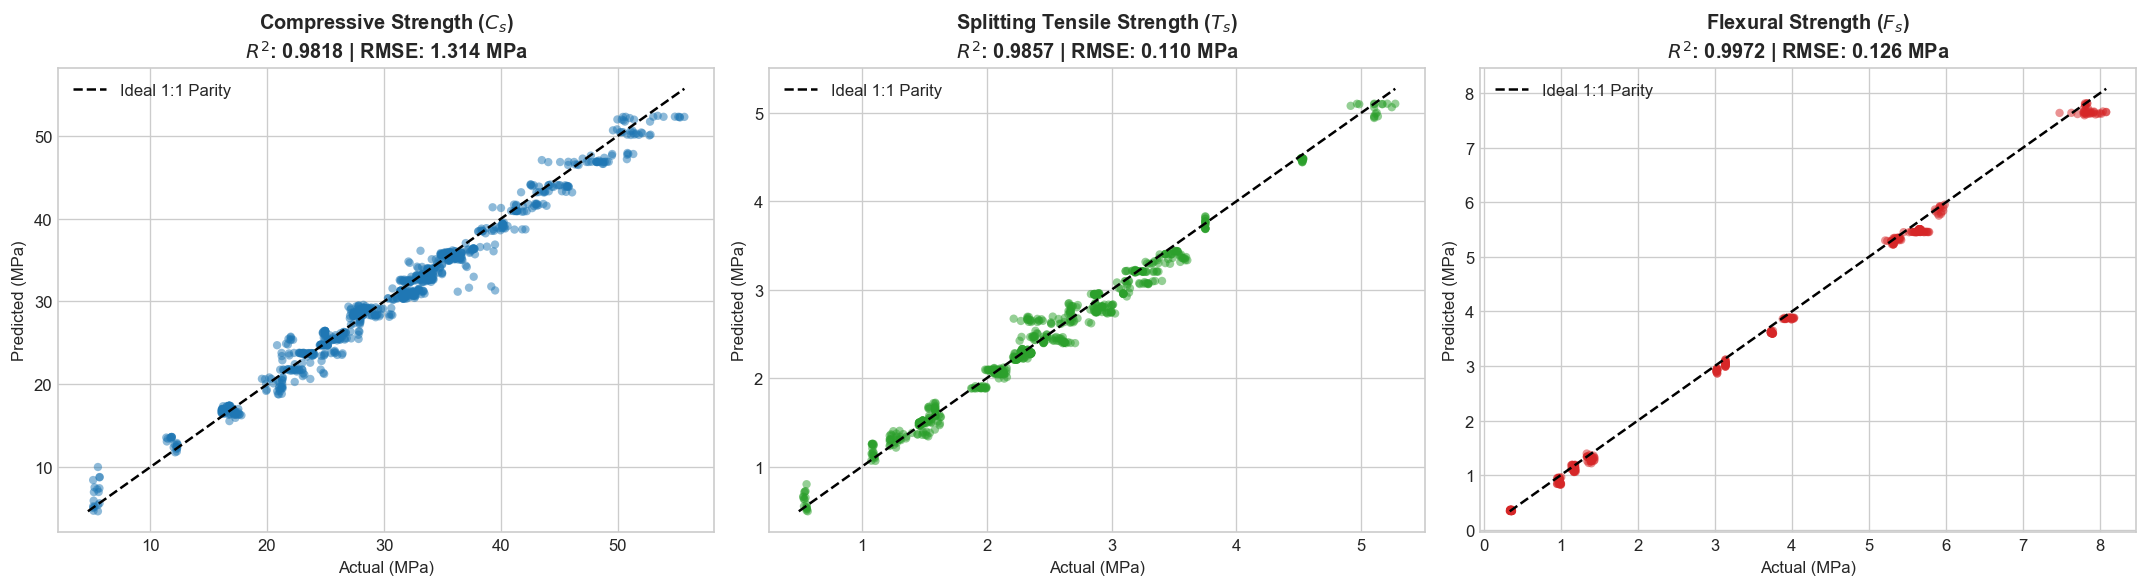

In [10]:
# Generate model predictions on test split
model.eval()
with torch.no_grad():
    test_preds_scaled = model(torch.tensor(X_test, dtype=torch.float32).to(device)).cpu().numpy()

# Denormalize predictions back to MPa physical units
test_preds_raw = test_preds_scaled * target_scales + target_centers

# Parity Plots (Predicted vs Actual)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ["#1f77b4", "#2ca02c", "#d62728"]
titles = ["Compressive Strength ($C_s$)", "Splitting Tensile Strength ($T_s$)", "Flexural Strength ($F_s$)"]

for i, col in enumerate(TARGET_COLS):
    valid_idx = mask_test[:, i] == 1.0
    y_true = y_test_raw[valid_idx, i]
    y_pred = test_preds_raw[valid_idx, i]
    
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    
    axes[i].scatter(y_true, y_pred, alpha=0.5, color=colors[i], edgecolors="none", s=25)
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    axes[i].plot([min_val, max_val], [min_val, max_val], 'k--', lw=1.5, label="Ideal 1:1 Parity")
    
    axes[i].set_title(f"{titles[i]}\n$R^2$: {r2:.4f} | RMSE: {rmse:.3f} MPa", fontweight="bold")
    axes[i].set_xlabel("Actual (MPa)")
    axes[i].set_ylabel("Predicted (MPa)")
    axes[i].legend(loc="upper left")

plt.tight_layout()
plt.show()


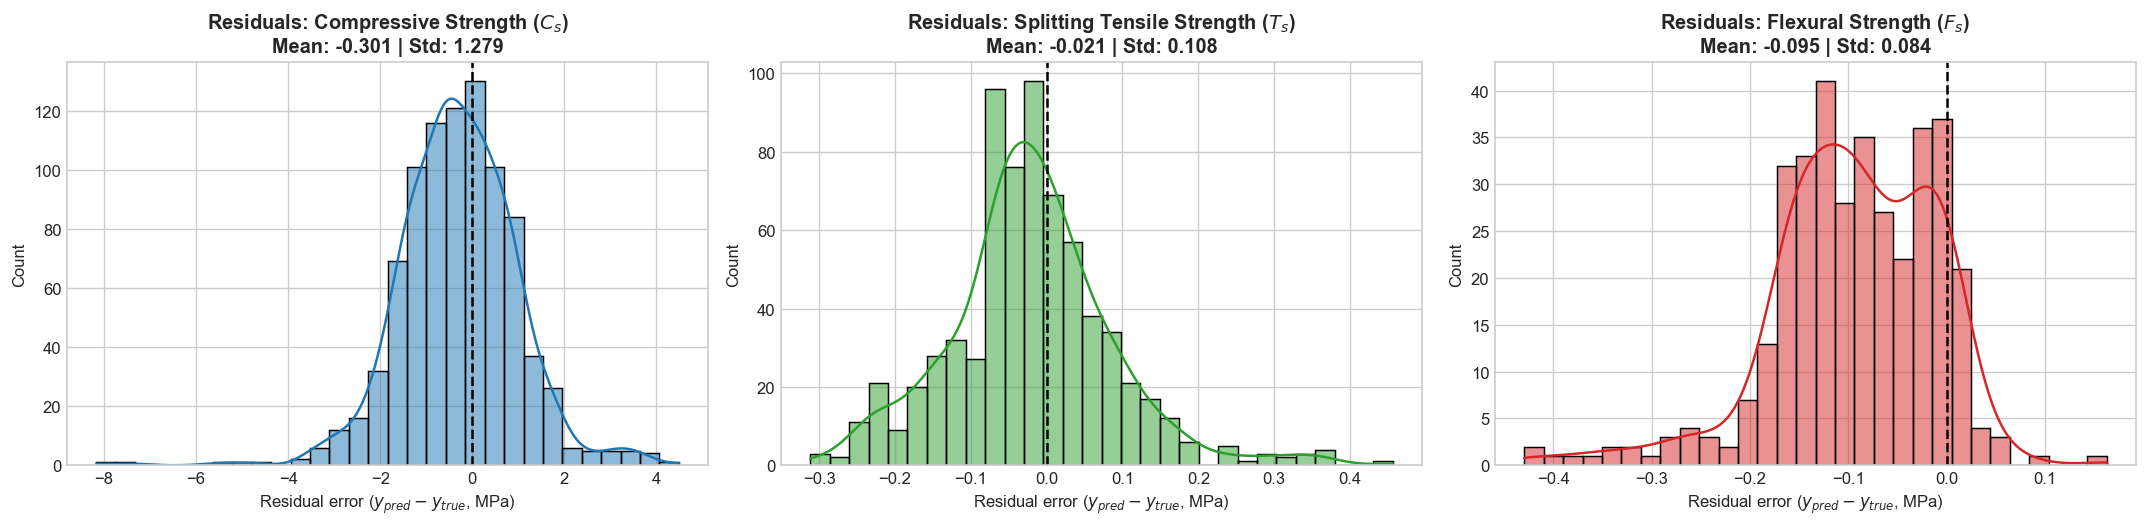

In [11]:
# Residuals Distribution Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for i, col in enumerate(TARGET_COLS):
    valid_idx = mask_test[:, i] == 1.0
    residuals = test_preds_raw[valid_idx, i] - y_test_raw[valid_idx, i]
    
    sns.histplot(residuals, kde=True, ax=axes[i], color=colors[i], bins=30)
    axes[i].axvline(0, color="black", linestyle="--", lw=1.5)
    axes[i].set_title(f"Residuals: {titles[i]}\nMean: {residuals.mean():.3f} | Std: {residuals.std():.3f}", fontweight="bold")
    axes[i].set_xlabel("Residual error ($y_{pred} - y_{true}$, MPa)")

plt.tight_layout()
plt.show()


## 10. Evaluation
We compute comprehensive quantitative metrics ($R^2$, RMSE, MAE) and verify adherence to mechanical domain constraints via the **Physical Violation Rate (PVR %)**:
$$PVR = 100 \times \frac{N_{\text{violating}}}{N_{\text{valid}}}$$


In [12]:
# Quantitative Metrics Summary Table
eval_rows = []
for i, col in enumerate(TARGET_COLS):
    valid_idx = mask_test[:, i] == 1.0
    y_true = y_test_raw[valid_idx, i]
    y_pred = test_preds_raw[valid_idx, i]
    
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    n_obs = valid_idx.sum()
    
    eval_rows.append({
        "Target": col,
        "Observed N": n_obs,
        "Coverage (%)": f"{(n_obs / len(test_df)) * 100:.1f}%",
        "R2 Score": f"{r2:.4f}",
        "RMSE (MPa)": f"{rmse:.4f}",
        "MAE (MPa)": f"{mae:.4f}"
    })

eval_df = pd.DataFrame(eval_rows)
print("--- Test Set Performance Metrics ---")
display(eval_df)

# Physical Violation Rate (PVR) Evaluation on Predicted Ratios across ALL 884 test mixes
cs_test_pred = np.maximum(test_preds_raw[:, 0], 1.0)
ts_test_pred = test_preds_raw[:, 1]
fs_test_pred = test_preds_raw[:, 2]

pred_rt = ts_test_pred / cs_test_pred
pred_rf = fs_test_pred / cs_test_pred

pvr_rt = np.mean((pred_rt < 0.06) | (pred_rt > 0.18)) * 100.0
pvr_rf = np.mean((pred_rf < 0.08) | (pred_rf > 0.25)) * 100.0
pvr_impossible = np.mean(ts_test_pred >= cs_test_pred) * 100.0

print("\n--- Physical Violation Rate (PVR) ---")
print(f"Tensile Ratio Violations (Rt outside [0.06, 0.18])  : {pvr_rt:.2f}%")
print(f"Flexural Ratio Violations (Rf outside [0.08, 0.25]) : {pvr_rf:.2f}%")
print(f"Physically Impossible Preds (Ts >= Cs)             : {pvr_impossible:.2f}%")


--- Test Set Performance Metrics ---


,Target,Observed N,Coverage (%),R2 Score,RMSE (MPa),MAE (MPa)
0,Cs_Mpa,884,100.0%,0.9818,1.3143,0.9931
1,Ts_Mpa,696,78.7%,0.9857,0.1097,0.0820
2,Fs_Mpa,363,41.1%,0.9972,0.1262,0.0990



--- Physical Violation Rate (PVR) ---
Tensile Ratio Violations (Rt outside [0.06, 0.18])  : 3.51%
Flexural Ratio Violations (Rf outside [0.08, 0.25]) : 17.99%
Physically Impossible Preds (Ts >= Cs)             : 0.00%


## 11. Model Saving and Inference Verification
We save the trained model weights and preprocessing artifacts into the `models/` directory, and demonstrate loading the saved model to perform inference on a fresh batch of concrete samples.


In [13]:
models_dir = os.path.join(project_root, "models")
os.makedirs(models_dir, exist_ok=True)

model_save_path = os.path.join(models_dir, "pim_mtl_model.pt")
preproc_save_path = os.path.join(models_dir, "preprocessor.joblib")

# Save trained PyTorch model using its built-in method
model.save(model_save_path, extra={"epochs": EPOCHS, "seed": SEED, "input_dim": input_dim})
print(f"Model successfully saved to: {model_save_path}")

# Save preprocessing pipeline for inference
joblib.dump(preprocessor_metadata, preproc_save_path)
print(f"Preprocessing metadata saved to: {preproc_save_path}")

# --- Verification: Reload model and run inference on 5 test specimens ---
print("\n--- Reloading Model and Performing Inference Demonstration ---")
loaded_model = PIM_MTL_Net.load(model_save_path, map_location="cpu")
loaded_model.eval()

loaded_preproc = joblib.load(preproc_save_path)

sample_X = torch.tensor(X_test[:5], dtype=torch.float32)
with torch.no_grad():
    sample_preds_scaled = loaded_model(sample_X).numpy()

sample_preds_orig = sample_preds_scaled * loaded_preproc["target_scales"] + loaded_preproc["target_centers"]

inference_demo_df = pd.DataFrame(
    sample_preds_orig,
    columns=["Predicted_Cs_Mpa", "Predicted_Ts_Mpa", "Predicted_Fs_Mpa"]
)
inference_demo_df["Predicted_Rt"] = inference_demo_df["Predicted_Ts_Mpa"] / inference_demo_df["Predicted_Cs_Mpa"]
inference_demo_df["Predicted_Rf"] = inference_demo_df["Predicted_Fs_Mpa"] / inference_demo_df["Predicted_Cs_Mpa"]

print("Sample Predictions on 5 Test Specimens:")
display(inference_demo_df.round(3))


Model successfully saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\models\pim_mtl_model.pt
Preprocessing metadata saved to: c:\Users\jeetu\projects\Capstone\3rdYearsem5\models\preprocessor.joblib

--- Reloading Model and Performing Inference Demonstration ---
Sample Predictions on 5 Test Specimens:


,Predicted_Cs_Mpa,Predicted_Ts_Mpa,Predicted_Fs_Mpa,Predicted_Rt,Predicted_Rf
0,19.490000,1.366,3.047,0.070,0.156
1,25.507000,2.110,3.886,0.083,0.152
2,41.804001,2.285,4.721,0.055,0.113
3,41.705002,2.289,4.673,0.055,0.112
4,31.292999,2.671,3.108,0.085,0.099
